---
title: "Simple Interaction"
subtitle: "DS 2023 | Communicating with Data"
---

## Overview

## Set up

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from ipywidgets import interact

import ipywidgets as widgets
from IPython.display import display

In [3]:
slider = widgets.IntSlider(value=5, min=0, max=10)
display(slider)

IntSlider(value=5, max=10)

In [4]:
sns.set_style('white')

In [5]:
data_url = "https://virginia.box.com/shared/static/eqpwseity23af9la6ppowkgv2ho4rvmz.csv"
reviews = pd.read_csv(data_url).set_index("obs_id")
reviews.head()

,title,country,province,variety,taster,price,points,content
obs_id,,,,,,,,
0,Nicosia 2013 Vulkà Bianco (Etna) Vulkà Bianc...,Italy,Sicily & Sardinia,White Blend,Kerin O’Keefe,NaN,87,"Aromas include tropical fruit, broom, brimston..."
1,Quinta dos Avidagos 2011 Avidagos Red (Douro)...,Portugal,Douro,Portuguese Red,Roger Voss,15.0,87,"This is ripe and fruity, a wine that is smooth..."
2,Rainstorm 2013 Pinot Gris (Willamette Valley)...,US,Oregon,Pinot Gris,Paul Gregutt,14.0,87,"Tart and snappy, the flavors of lime flesh and..."
3,St. Julian 2013 Reserve Late Harvest Riesling...,US,Michigan,Riesling,Alexander Peartree,13.0,87,"Pineapple rind, lemon pith and orange blossom ..."
4,Sweet Cheeks 2012 Vintner's Reserve Wild Chil...,US,Oregon,Pinot Noir,Paul Gregutt,65.0,87,"Much like the regular bottling from 2012, this..."


## Using `@interact()`

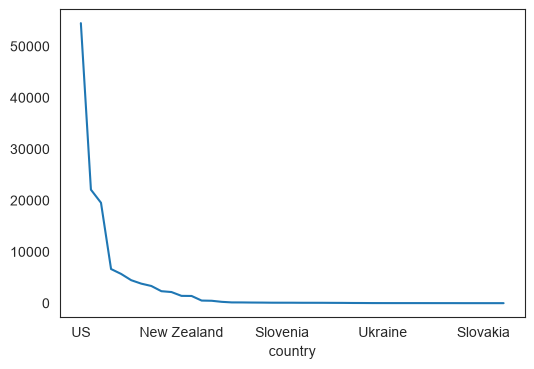

In [6]:
reviews['country'].value_counts().plot(figsize=(6,4), kind='line')
plt.show()

In [7]:
@interact()
def plot_country_counts(w=6, h=4, kind='line'):
    reviews['country'].value_counts().plot(figsize=(w,h), kind=kind)

interactive(children=(IntSlider(value=6, description='w', max=18, min=-6), IntSlider(value=4, description='h',…

In [8]:
@interact(
    kind=['bar', 'barh', 'line','pie'],
    ascend=[True, False]
)
def plot_country_counts(w=6, h=4, kind='line', ascend=False):
    reviews['country'].value_counts().sort_values(ascending=ascend).plot(figsize=(w,h), kind=kind)

interactive(children=(IntSlider(value=6, description='w', max=18, min=-6), IntSlider(value=4, description='h',…

In [9]:
group_cols = ['country', 'taster', 'variety', 'points']

In [10]:
@interact(
    kind=['bar', 'barh', 'line','pie'],
    ascend=[True, False],
    group=group_cols
)
def plot_group_counts(group='country', w=6, h=4, kind='line', ascend=False):
    reviews[group].value_counts().sort_values(ascending=ascend).plot(figsize=(w,h), kind=kind)

interactive(children=(Dropdown(description='group', options=('country', 'taster', 'variety', 'points'), value=…

In [11]:
reviews_top = reviews.loc[reviews['country'].isin(reviews.value_counts('country').index[:7])]
reviews_top[['taster', 'country']] = reviews_top[['taster', 'country']].astype('category')

In [12]:
@interact(color=['taster', 'country'], h=(100,1000,1), w=(100,2000,1))
def plot_alluvial(color='taster', h=800, w=1000):
    fig = px.parallel_categories(
        reviews_top, 
        dimensions=['taster', 'country'], 
        color=reviews_top[color].cat.codes, 
        width=w, height=h
    )
    fig.update_traces(line_shape='hspline')
    fig.update_layout(coloraxis_showscale=False)
    fig.show()

interactive(children=(Dropdown(description='color', options=('taster', 'country'), value='taster'), IntSlider(…

We can also view this as a heatmap.

In [13]:
@interact(
    min_n = (0,100,1),
    cmap = sorted([cmap for cmap in plt.colormaps if '_r' not in cmap]),
    cmap_r = [True, False],
    transpose = [True, False],
    axis={
        '0':0, '1':1, "Both": None}
)
def plot_country_taster(
    min_n=0, 
    cmap='YlGnBu', 
    cmap_r=False, 
    transpose=True,
    axis=None
):
    if cmap_r:
        cmap = cmap + '_r'
    country_taster = reviews_top.value_counts(['country','taster'])
    country_taster = country_taster[country_taster > min_n]
    if transpose:
        country_taster = country_taster.unstack(fill_value=0).T
    else:
        country_taster = country_taster.unstack(fill_value=0)
    display(country_taster.style.background_gradient(axis=axis, cmap=cmap))

interactive(children=(IntSlider(value=0, description='min_n'), Dropdown(description='cmap', index=35, options=…

First, let's prepare a separate dataframe for the two variables.

In [14]:
price_point = reviews_top[['price','points']].dropna().copy()
price_point['price'] = price_point['price'].astype(int)
price_point.head()

,price,points
obs_id,,
1,15,87
2,14,87
3,13,87
4,65,87
5,15,87


In [15]:
ppvc = price_point.value_counts(['price','points']).sort_index().unstack(fill_value=0)

In [16]:
@interact(
    # price=sorted(price_point.price.unique())
    price=(5,1000,5)
)
def plot_median_points(price = 20):
    fig, ax = plt.subplots()
    plt.xlim(80,100)
    try:
        S = ppvc.loc[price]
    except KeyError as e:
        ax.text(.5, .5, f"{price} not found in dataset.", transform=ax.transAxes, ha='center', va='center', fontsize=18)
        plt.xlim(80,100)
        return 
    S.plot.bar(rot=0, color=[('tab:red' if x == S.idxmax() else 'lightgray') for x in S.index], ax=ax)
    plt.title(f"Distribution of Points for ${price} Wines")
    plt.show()

interactive(children=(IntSlider(value=20, description='price', max=1000, min=5, step=5), Output()), _dom_class…

Note that neither a histogram nor a density plot shows the pattern of five dollar clustering, even if we adjust binning.

In [17]:
@interact(
    bins=(1,100,1),
    bw=(.1,2.0,.1),
    col=['price', 'points']
)
def plot_hist(col='price', bins=30, bw=.5):
    fig, ax = plt.subplots(1, 2, figsize=(10,4), layout='constrained')
    price_point.head(50)[col].plot.hist(ax=ax[0], bins=bins)
    price_point.head(50)[col].plot.density(ax=ax[1], bw_method=bw)
    plt.show()

interactive(children=(Dropdown(description='col', options=('price', 'points'), value='price'), IntSlider(value…

## Getting fancy

In [18]:
import ipywidgets as widgets

In [28]:
@interact(
    kind=['bar', 'barh', 'line','pie'],
    ascend=widgets.Checkbox(False, description='Ascending?')
)
def plot_country_counts(w=6, h=4, kind='line', ascend=False):
    reviews['country'].value_counts()\
        .sort_values(ascending=ascend)\
        .plot(figsize=(w,h), kind=kind)

interactive(children=(IntSlider(value=6, description='w', max=18, min=-6), IntSlider(value=4, description='h',…

In [23]:
widgets.Checkbox?

Init signature: widgets.Checkbox(value=None, **kwargs)
Docstring:     
Displays a boolean `value` in the form of a checkbox.

Parameters
----------
value : {True,False}
    value of the checkbox: True-checked, False-unchecked
description : str
        description displayed next to the checkbox
indent : {True,False}
    indent the control to align with other controls with a description. The style.description_width attribute controls this width for consistence with other controls.
Init docstring: Public constructor
File:           /opt/miniconda3/envs/ds2023/lib/python3.12/site-packages/ipywidgets/widgets/widget_bool.py
Type:           MetaHasTraits
Subclasses:     